# 04 - Why / Why not: luyện phản biện lựa chọn

Notebook tra nhanh Q59-Q80. Mỗi câu trả lời theo bốn nhịp: **chọn gì → vì sao phù hợp → đánh đổi gì → bằng chứng/giới hạn nào**.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

def find_repo_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'Defense_Package').is_dir(): return path
    raise FileNotFoundError('Không tìm thấy repository root')

ROOT = find_repo_root()
EVIDENCE = ROOT / 'Defense_Package' / '02_Defense_Evidence'
ANSWERS = ROOT / 'Defense_Package' / '01_Committee_QnA' / 'Answers'
print('Answers:', ANSWERS)

Answers: d:\NCKH_2026\NCKH_2026_AIOT\Defense_Package\01_Committee_QnA\Answers


## 1. Ma trận phản biện nhanh

Dùng bảng để xác định đúng câu, sau đó mở file `Answers/Qxx.md` nếu hội đồng hỏi sâu.

In [2]:
rows = [
 ('Q59','Dataset','Patient-ID split','Random file split','Chống leakage giữa các bản ghi cùng người'),
 ('Q60','Dataset','Binary Asthma/Non-Asthma','Đa lớp bệnh','Đúng phạm vi sàng lọc và độ phủ nhãn hiện có'),
 ('Q61','Dataset','Có Playback','Chỉ WAV gốc','Phủ domain loa-không gian-INMP441; bằng chứng không hoàn toàn một chiều'),
 ('Q62','Dataset','Silence qua gate','Silence là Non-Asthma','Không để model học lối tắt theo năng lượng'),
 ('Q63','DSP','Cửa sổ 5 s','1-2 s hoặc dài hơn','Cân bằng ngữ cảnh, RAM và độ trễ'),
 ('Q64','DSP','Không pre-emphasis','α=0.97','Ổn định seed và giảm bước DSP/nhiễu cao tần'),
 ('Q65','DSP','Factorial C4','Ghép winner OFAT','Đo tương tác giữa các tham số'),
 ('Q66','Model','V1 end-to-end','Chọn model FP32 Accuracy cao nhất','Có đủ lượng tử, parity và log phần cứng'),
 ('Q67','Model','Checkpoint seed 44','Một seed bất kỳ','Artifact tái lập; độ ổn định phải báo cáo nhiều seed'),
 ('Q68','Quant','QAT INT8 C4 s44','FP32/PTQ/INT16x8','Cân bằng metric, kích thước và chạy ESP32'),
 ('Q69','Metric','Recall/FN + nhiều tiêu chí','Chỉ Accuracy','Bài toán mất cân bằng và chi phí bỏ sót Asthma'),
 ('Q70','Decision','Ngưỡng hiệu chuẩn','0.5 mặc định','Tối ưu trade-off FN/FP cho đúng model'),
 ('Q71','Acquisition','VAD + Quality Gate','Một ngưỡng duy nhất','Trigger khác với chất lượng toàn cửa sổ'),
 ('Q72','Acquisition','VAD ngưỡng nhẹ','Neural VAD','Ít RAM, độ trễ, dễ hiệu chỉnh'),
 ('Q73','Edge AI','Suy luận tại Node','Gateway/Cloud','Riêng tư, offline, giảm dữ liệu truyền'),
 ('Q74','Network','ESP-NOW','BLE/Wi-Fi trực tiếp','Gói nhỏ, không cần TCP/MQTT trên Node'),
 ('Q75','Security','AES-GCM + sequence','CRC','Bí mật, xác thực và chống replay'),
 ('Q76','FSM','3 lần + vote','Một lần/liên tục','Giảm ảnh hưởng cửa sổ bất thường và có điểm kết thúc'),
 ('Q77','Vitals','Tách AI và vitals','Fusion ngay','Chưa có dataset multimodal đồng bộ'),
 ('Q78','Packet','0 là sentinel','NaN','Packet cố định; nên nâng cấp thêm cờ valid'),
 ('Q79','Reliability','Nêu rõ giới hạn','Tuyên bố không mất dữ liệu','Chưa có persistent store-and-forward'),
 ('Q80','Verification','PCM16 parity + hash/log','Chỉ nhìn Accuracy Python','Truy vết từ input đến ESP32')
]
tradeoffs = pd.DataFrame(rows, columns=['Q','Nhóm','Lựa chọn hiện tại','Phương án đối chiếu','Ý trả lời trong một câu'])
display(tradeoffs)

,Q,Nhóm,Lựa chọn hiện tại,Phương án đối chiếu,Ý trả lời trong một câu
0,Q59,Dataset,Patient-ID split,Random file split,Chống leakage giữa các bản ghi cùng người
1,Q60,Dataset,Binary Asthma/Non-Asthma,Đa lớp bệnh,Đúng phạm vi sàng lọc và độ phủ nhãn hiện có
2,Q61,Dataset,Có Playback,Chỉ WAV gốc,Phủ domain loa-không gian-INMP441; bằng chứng ...
3,Q62,Dataset,Silence qua gate,Silence là Non-Asthma,Không để model học lối tắt theo năng lượng
4,Q63,DSP,Cửa sổ 5 s,1-2 s hoặc dài hơn,"Cân bằng ngữ cảnh, RAM và độ trễ"
5,Q64,DSP,Không pre-emphasis,α=0.97,Ổn định seed và giảm bước DSP/nhiễu cao tần
6,Q65,DSP,Factorial C4,Ghép winner OFAT,Đo tương tác giữa các tham số
7,Q66,Model,V1 end-to-end,Chọn model FP32 Accuracy cao nhất,"Có đủ lượng tử, parity và log phần cứng"
8,Q67,Model,Checkpoint seed 44,Một seed bất kỳ,Artifact tái lập; độ ổn định phải báo cáo nhiề...
9,Q68,Quant,QAT INT8 C4 s44,FP32/PTQ/INT16x8,"Cân bằng metric, kích thước và chạy ESP32"


## 2. Bốn hình nên mở nhiều nhất

Các hình này lần lượt trả lời về dataset/domain, C4, lượng tử và triển khai phần cứng.

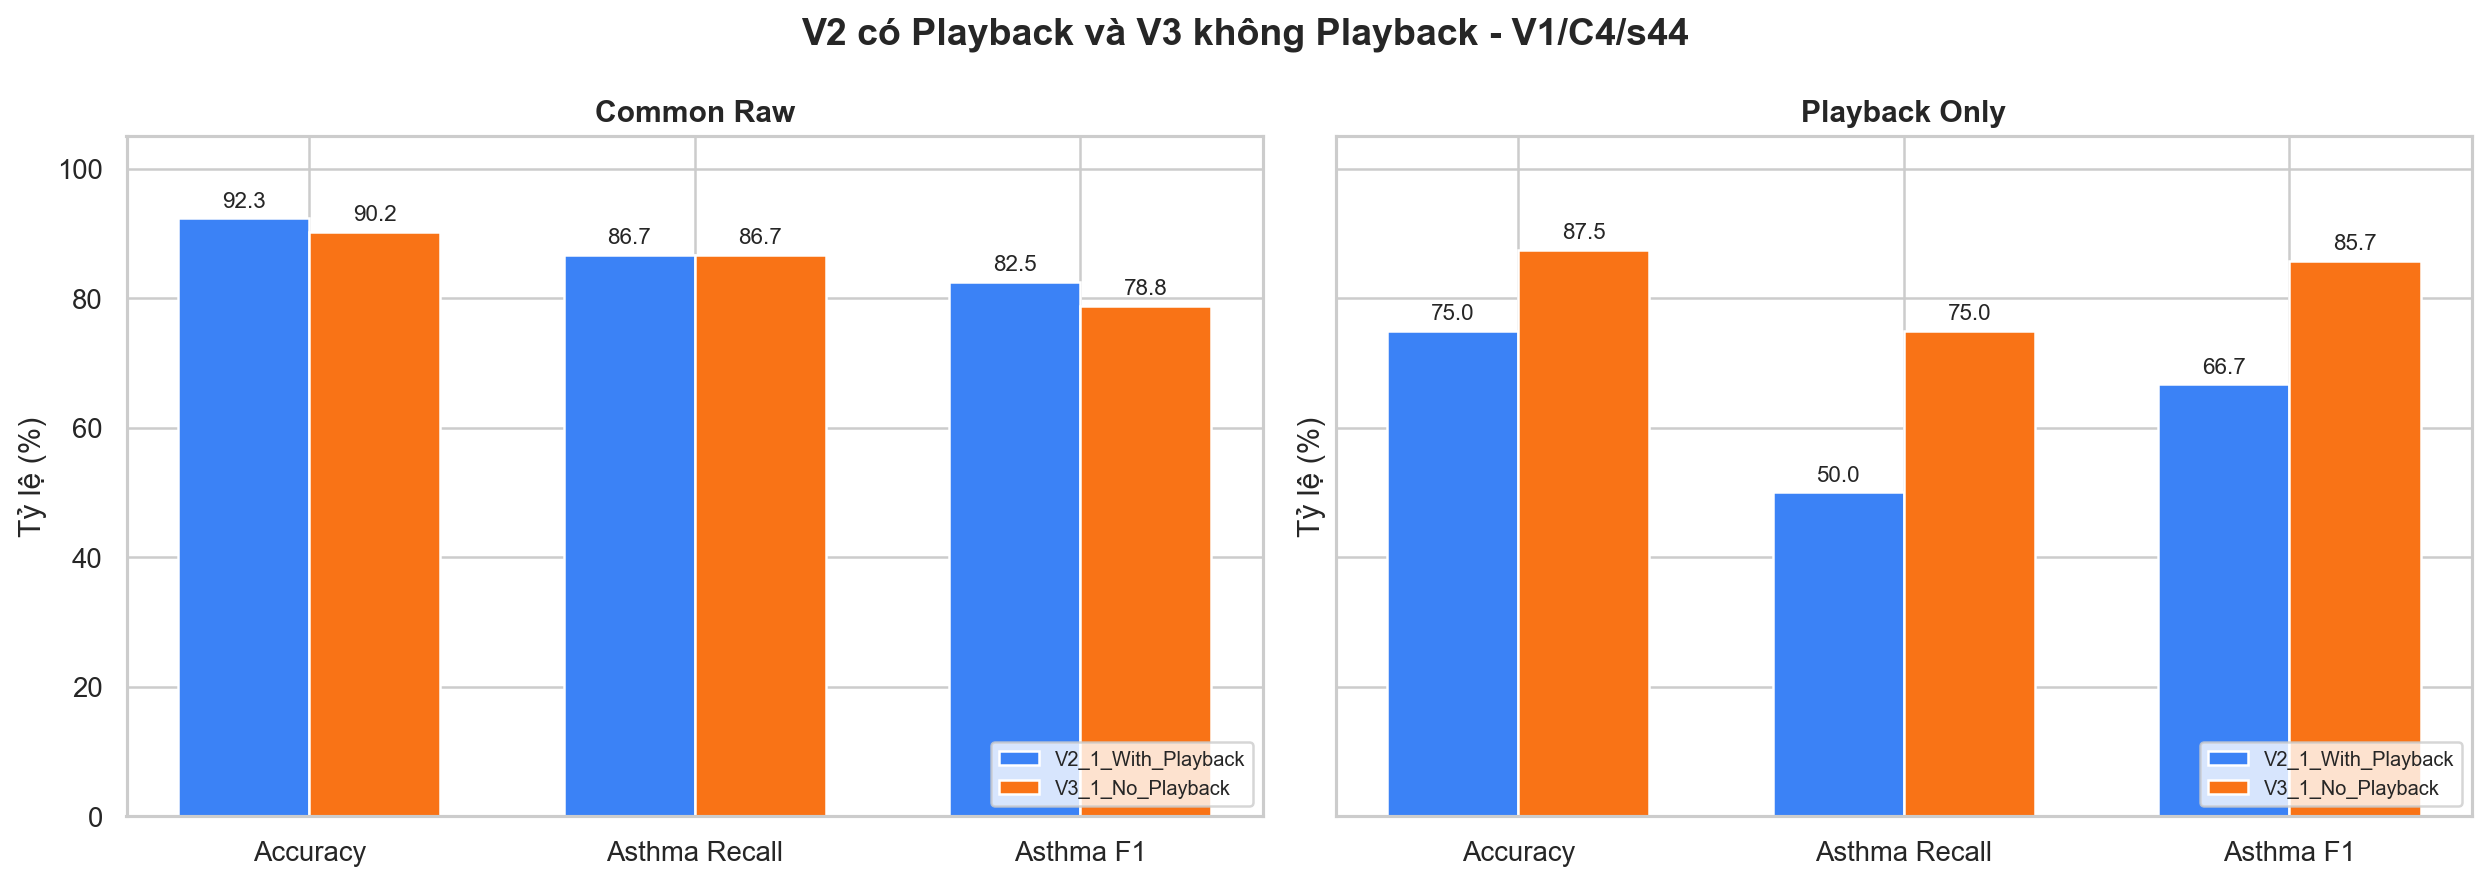

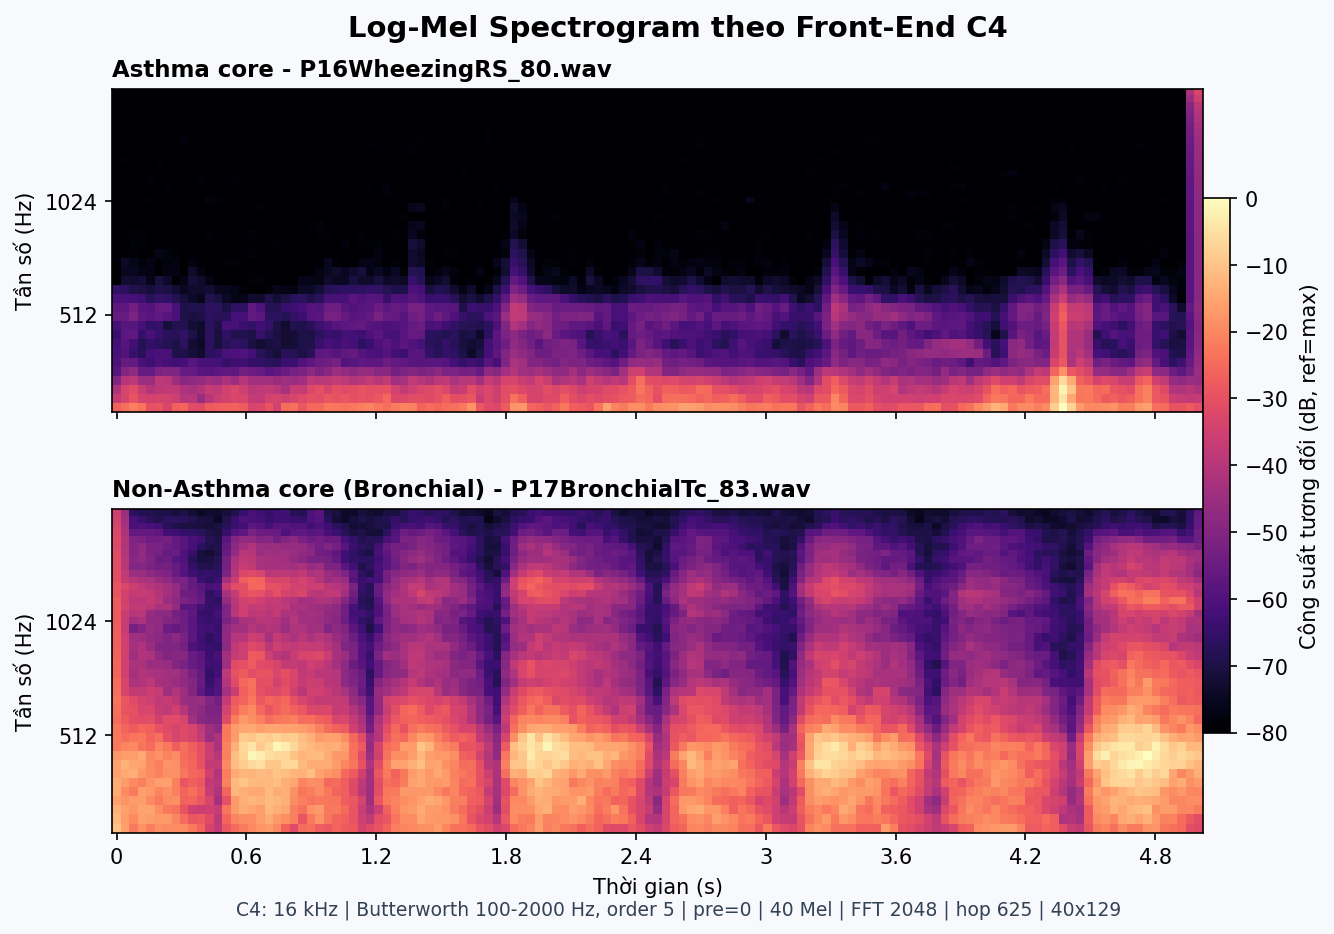

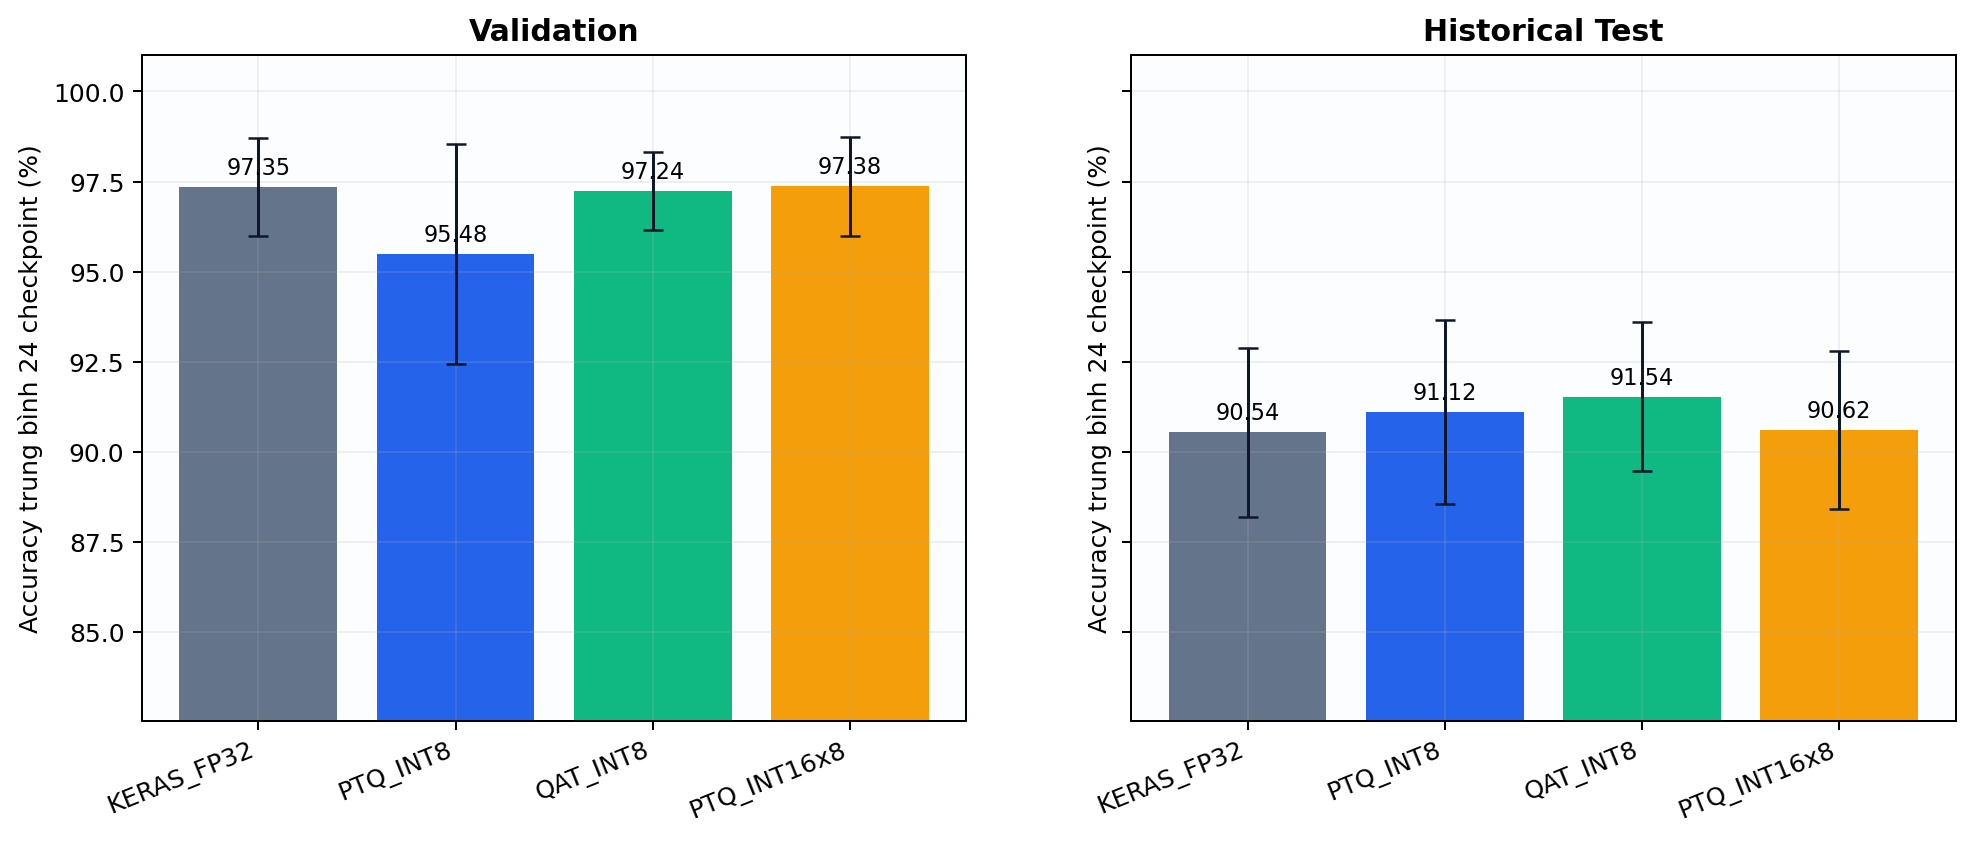

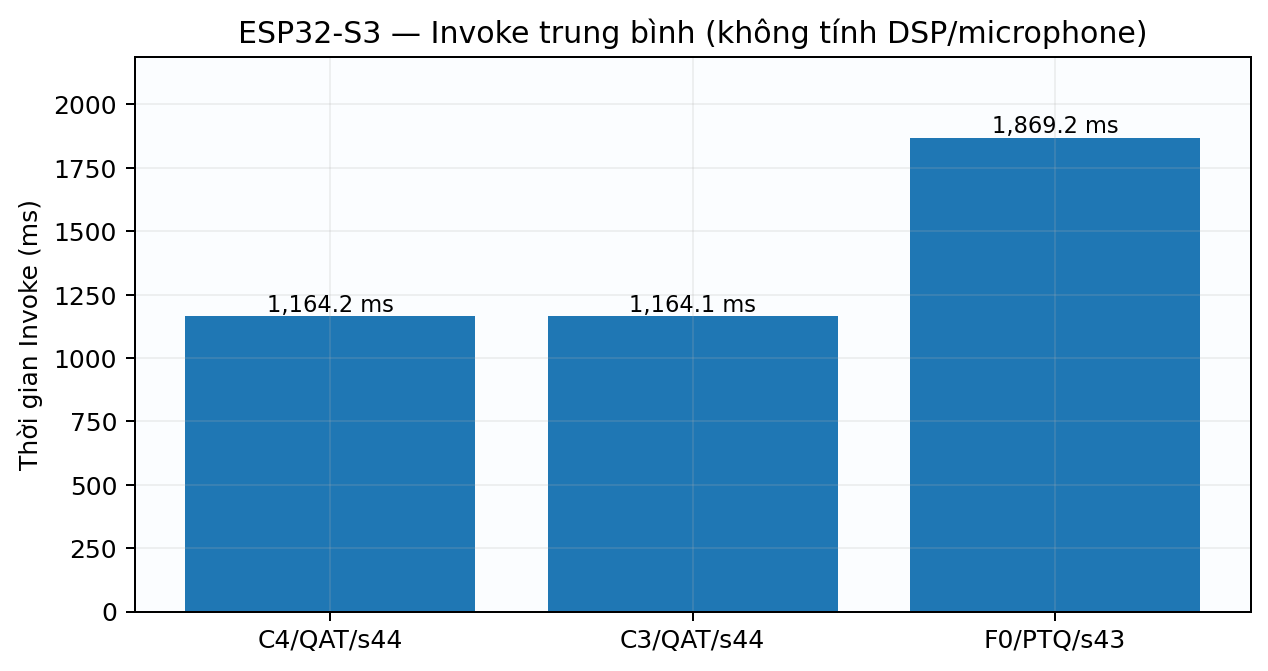

In [3]:
for rel in [
 'figures/01_Dataset/03_Playback_Ablation_V2_V3.png',
 'figures/02_DSP/05_C4_LogMel_Disease_Comparison.png',
 'figures/03_AI_Model/04_Quantization_Method_Overview.png',
 'figures/05_Deployment/01_ESP32_Invoke_Logs.png',
]:
    display(Image(filename=str(EVIDENCE / rel), width=1050))

## 3. Mẫu trả lời 30 giây

**Ví dụ Q68:** “Nhóm không giả định QAT luôn tốt hơn PTQ. Chúng tôi đánh giá FP32, PTQ INT8, PTQ INT16x8 và QAT INT8 trên cùng Validation/Test, xem thêm Asthma FN, kích thước và log ESP32. Với checkpoint C4 s44, QAT INT8 là phương án cân bằng được chọn; kết luận chỉ áp dụng cho artifact đã đo.”

**Ví dụ Q66:** “Một số kiến trúc có FP32 Accuracy cao hơn V1 trong một bảng. V1 được chọn không phải vì thắng tuyệt đối, mà vì có chuỗi bằng chứng end-to-end hoàn chỉnh nhất: C4, QAT INT8, parity Python/C++, arena/latency và firmware. Đây là lựa chọn triển khai đa tiêu chí.”

## 4. Liên kết đáp án chi tiết

[Q59](../01_Committee_QnA/Answers/Q59.md) · [Q60](../01_Committee_QnA/Answers/Q60.md) · [Q61](../01_Committee_QnA/Answers/Q61.md) · [Q62](../01_Committee_QnA/Answers/Q62.md) · [Q63](../01_Committee_QnA/Answers/Q63.md) · [Q64](../01_Committee_QnA/Answers/Q64.md) · [Q65](../01_Committee_QnA/Answers/Q65.md) · [Q66](../01_Committee_QnA/Answers/Q66.md) · [Q67](../01_Committee_QnA/Answers/Q67.md) · [Q68](../01_Committee_QnA/Answers/Q68.md) · [Q69](../01_Committee_QnA/Answers/Q69.md) · [Q70](../01_Committee_QnA/Answers/Q70.md) · [Q71](../01_Committee_QnA/Answers/Q71.md) · [Q72](../01_Committee_QnA/Answers/Q72.md) · [Q73](../01_Committee_QnA/Answers/Q73.md) · [Q74](../01_Committee_QnA/Answers/Q74.md) · [Q75](../01_Committee_QnA/Answers/Q75.md) · [Q76](../01_Committee_QnA/Answers/Q76.md) · [Q77](../01_Committee_QnA/Answers/Q77.md) · [Q78](../01_Committee_QnA/Answers/Q78.md) · [Q79](../01_Committee_QnA/Answers/Q79.md) · [Q80](../01_Committee_QnA/Answers/Q80.md)